# 2.4 Photo coverage — selected substrate, colour/texture and forecast export

Photograph → **estimated visible projected surface coverage (%)**, overlay, ambiguity envelope and CSV for **2.5**. This does not measure internal colonisation or prove that white material is healthy mycelium.

**First use:** Run All to create `annotation_editor.html`. Open it locally, choose photos, trace the substrate boundary and optionally click examples of mycelium and exposed substrate. Download the annotation JSON. Put its path in `ANNOTATION_JSON`, set `IMAGE_ROOT` to the original-photo folder, and Run All again. Inspect/correct the overlays. Set `reviewed=true` only after checking the resulting segmentation, then rerun for forecast export. The browser tool works offline.

The selected visible substrate is the denominator: **no fixed central crop**. Whole-frame processing requires explicit confirmation. Glare/condensation inside the substrate belong in the uncertainty mask, not background exclusions. Methods need evaluation against reference annotations; no biological accuracy is claimed.

Dependencies: NumPy, pandas, Pillow, matplotlib, IPython. No mycodemo imports, global training on d005/syldd or external model downloads. Outputs go to `models/colonisation/`; original photos remain unchanged.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import base64, hashlib, io, json
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
import matplotlib.pyplot as plt
from IPython.display import display

WORK_DIR=Path('/home/sylas/Desktop/mycodemo').resolve()
IMAGE_ROOT=WORK_DIR/'data/raw/syldd_2026'
OUTPUT_PARENT=WORK_DIR/'models/colonisation'
ANNOTATION_JSON=None
INOCULATION_DATE=None
WRITE_OUTPUTS=True
BATCH_DEFAULTS={'batch_id':'syldd','species':'Pleurotus ostreatus','substrate':'straw','view_id':'top'}
BATCH_START_DATES={'syldd':'2026-10-08'}  # day 0 per batch; the day of a photo = its date minus this (INOCULATION_DATE is only a fallback)
VIEWS=('top','side','bottom')
from mycodemo.growth import traced_coverage as tc  # the counting code (outline, clicks, brush, %) lives here
from mycodemo.growth.traced_coverage import boolean, finite, circle as _circle
PHOTO_RECORDS=[  # two syldd dishes; hand-set circle + one example each, NOT reviewed (software demo only)
 {'image_path':'day_04/IMG_20261012_154516.jpg','batch_id':'syldd','sample_id':'SYLDD-WS10-D1','day':4,'roi':{'kind':'polygon','points':_circle(.51,.51,.42)},
  'seeds':[{'label':'mycelium','x':.255,'y':.365,'radius':.015},{'label':'substrate','x':.65,'y':.35,'radius':.015}],'reviewed':False},
 {'image_path':'day_08/IMG_20261016_154903.jpg','batch_id':'syldd','sample_id':'','day':8,'roi':{'kind':'polygon','points':_circle(.52,.49,.41)},
  'seeds':[{'label':'mycelium','x':.50,'y':.60,'radius':.015},{'label':'substrate','x':.70,'y':.77,'radius':.015}],'reviewed':False},
]  # actual records only; alternatively load the editor's JSON
# Each record: image_path, date (or day), batch_id, batch_start_date, sample_id, view (top/side/bottom), ROI or explicit whole-frame confirmation, optional seeds, brush strokes, correction polygons,
# reviewed (bool), selected_for_forecast (bool), method ('auto','seeded','cluster','hsv','manual').
PARAMETERS=tc.PARAMETERS  # one dict, shared with traced_coverage.py: a change here changes the counting there

def digest(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def output_path(relative):
    path=(WORK_DIR/relative).resolve()
    if not path.is_relative_to(WORK_DIR):raise ValueError('Output must stay inside the project folder.')
    return path
def input_path(value):
    path=Path(value).expanduser()
    return (path if path.is_absolute() else Path(IMAGE_ROOT)/path).resolve()
def json_safe(value):
    if isinstance(value,dict):return {str(k):json_safe(v) for k,v in value.items()}
    if isinstance(value,(list,tuple)):return [json_safe(v) for v in value]
    if isinstance(value,np.ndarray):return json_safe(value.tolist())
    if isinstance(value,np.generic):return json_safe(value.item())
    if isinstance(value,float) and not np.isfinite(value):return None
    return value
def record_hash(row):
    if row.get('image_sha256'):return row['image_sha256']
    try:return digest(input_path(row['image_path']))
    except (OSError,KeyError,TypeError):return None
def merge_records(builtin,from_json):
    # A photo that is in both lists (same file hash) is counted once, from the JSON.
    json_hashes={h for h in map(record_hash,from_json) if h}
    return [dict(r) for r in builtin if record_hash(r) not in json_hashes]+list(from_json)
source_hashes={};records=[dict(row) for row in PHOTO_RECORDS]
if ANNOTATION_JSON is not None:
    annotation_path=Path(ANNOTATION_JSON).expanduser().resolve();source_hashes[str(annotation_path)]=digest(annotation_path)
    document=json.loads(annotation_path.read_text())
    if document.get('schema_version')!=1 or not isinstance(document.get('photos'),list):raise ValueError('Expected annotation schema_version=1 and photos list.')
    json_hashes={h for h in map(record_hash,document['photos']) if h}
    records=merge_records(records,document['photos'])
    print('Photos in both PHOTO_RECORDS and the JSON (same file): the JSON record is used:',sum(record_hash(r) in json_hashes for r in PHOTO_RECORDS))
print('Photo records:',len(records))
if not records:print('No photos supplied. Run All to generate the editor; no cultivation measurements are invented.')

Photo records: 2


## 1. Explicit substrate masks and aligned images

Images are EXIF-oriented, then reduced to a maximum side of 1000 pixels. Saved masks/counts use working resolution; original dimensions/hashes are retained. Polygon/seed coordinates are normalized 0–1 in that oriented image. ROI polygons, external binary masks, or explicit whole-frame confirmation are supported. Background holes are allowed; do not remove glare/unknown substrate from the denominator.

In [2]:
from mycodemo.growth.traced_coverage import load_photo,polygon_points,polygon_mask

def external_mask(path,shape,original_size):
    with Image.open(path) as raw:
        if raw.mode not in ('1','L'):raise ValueError('External mask must be single-channel binary.')
        image=raw.convert('L')
        if not set(np.unique(np.asarray(image))).issubset({0,255}):raise ValueError('External mask must use 0 and 255.')
        expected=(shape[1],shape[0])
        if image.size not in (tuple(original_size),expected):raise ValueError('Mask must match oriented original or working dimensions.')
        if image.size!=expected:image=image.resize(expected,Image.Resampling.NEAREST)
        return np.asarray(image)>127

def substrate_mask(record,shape,original_size):
    external=None
    if record.get('roi_mask_path') is not None and record.get('roi') is None and not record.get('full_frame_substrate_confirmed'):
        path=input_path(record['roi_mask_path']);source_hashes[str(path)]=digest(path);external=external_mask(path,shape,original_size)
    return tc.substrate_mask(record,shape,external)

import re
def photo_date(path):
    """Date the photo was taken as YYYY-MM-DD: EXIF DateTimeOriginal, else IMG_YYYYMMDD_HHMMSS in the file name, else ''."""
    try:
        with Image.open(path) as raw:taken=str(raw.getexif().get_ifd(0x8769).get(0x9003) or '')
        if re.match(r'\d{4}:\d{2}:\d{2}',taken) and not taken.startswith('0000'):return taken[:10].replace(':','-')
    except (OSError,ValueError,KeyError,AttributeError):pass
    m=re.search(r'(\d{4})(\d{2})(\d{2})_\d{6}',Path(path).name)
    if m:
        try:return pd.Timestamp(f'{m[1]}-{m[2]}-{m[3]}').strftime('%Y-%m-%d')
        except ValueError:pass
    return ''


## 2. Per-image colour and texture methods

**Auto** uses labelled examples when both mycelium and exposed-substrate clicks are supplied; otherwise it previews Lab/texture clustering. A bright low-chroma cluster is only a candidate, not biological identity. HSV is retained as a comparison baseline. Manual mode begins with all substrate pixels uncertain, then accepts correction polygons.

Features: Lab lightness/colour, local brightness variation, edge magnitude and saturation. Sample pixels from a click are correlated; they are not independent biological training observations. Clicks must be inside the ROI and contradictory seed patches cannot overlap. No general classifier is trained on d005/syldd.

In [3]:
# Moved to mycodemo/growth/traced_coverage.py (also used by the app's Check image page).
from mycodemo.growth.traced_coverage import (box_mean,image_features,hsv_candidate,nearest_centres,cluster_candidate,
    seed_masks,seeded_candidate,stroke_mask,segment)

## 3. Coverage, ambiguity and quality

Coverage = nominal mycelium pixels / substrate-mask pixels × 100. Ambiguous pixels remain in the denominator. The lower bound counts only non-ambiguous mycelium; the upper counts all ambiguous pixels as potentially mycelium. The nominal value retains the algorithm's guess in ambiguous regions. This is an ambiguity envelope, **not a confidence interval or complete error bound**.

Review is required for forecast export. Excessive ambiguity, very dark images, missing dates or duplicate selected measurements block export. Glare and blur statistics are heuristic aids, not validated quality tests. The minimum 10 percentage-point forecast tolerance is an explicit demo weighting assumption. Human review does not make biological identity certain.

In [4]:
from mycodemo.growth.traced_coverage import coverage_statistics,photo_quality,overlay_image

def day_from_dates(date,start):
    observed,begin=pd.Timestamp(date),pd.Timestamp(start)
    if pd.isna(observed) or pd.isna(begin):raise ValueError('Invalid date.')
    observed,begin=[t.tz_localize(None) if t.tzinfo else t for t in (observed,begin)]
    return (observed.normalize()-begin.normalize()).days  # whole calendar days; the time of day is ignored

def batch_start(record):
    return record.get('batch_start_date') or BATCH_START_DATES.get(str(record.get('batch_id') or BATCH_DEFAULTS['batch_id'])) or INOCULATION_DATE

def observation_day(record):
    day=None if record.get('day') is None else finite(record['day'],'day',0)
    if record.get('date') not in (None,''):
        start=batch_start(record)
        if not start:
            if day is None:return None,'Date needs a batch start date (or INOCULATION_DATE) or an elapsed day.'
        else:
            derived=finite(day_from_dates(record['date'],start),'day worked out from date and batch start date',0)
            if day is not None and not np.isclose(day,derived):raise ValueError('day/date disagree.')
            day=derived
    return (day,None) if day is not None else (None,'Enter the photo date and the batch start date.')

def analyse_record(record,index):
    path=input_path(record['image_path']);sha=digest(path);source_hashes[str(path)]=sha
    if record.get('image_sha256') not in (None,'',sha):raise ValueError('Source image hash differs from annotation.')
    rgb,original_size=load_photo(path);metadata={k:record.get(k) or v for k,v in BATCH_DEFAULTS.items()}
    if record.get('view') not in (None,'') and record['view'] not in VIEWS:raise ValueError('view must be top, side or bottom.')
    metadata['view_id']=record.get('view') or record.get('view_id') or BATCH_DEFAULTS['view_id'];metadata['sample_id']=str(record.get('sample_id') or '').strip()
    metadata['batch_start_date']=str(batch_start(record) or '');metadata['date']=str(record.get('date') or '')
    if not str(metadata['batch_id']).strip():raise ValueError('batch_id required.')
    entry={'index':index,'image_path':str(path),'image_sha256':sha,'photo_id':str(record.get('photo_id') or sha),**metadata,
           'original_width':original_size[0],'original_height':original_size[1],'working_width':rgb.shape[1],'working_height':rgb.shape[0],
           'reviewed':boolean(record.get('reviewed',False),'reviewed'),'selected_for_forecast':boolean(record.get('selected_for_forecast',True),'selected_for_forecast')}
    roi,message=substrate_mask(record,rgb.shape[:2],original_size)
    if roi is None:return {'entry':{**entry,'status':'needs_substrate_boundary','quality_ok':False,'notes':[message]},'rgb':rgb,'record':record}
    mask,uncertain,details,channels,comparison=segment(rgb,roi,record);stats=coverage_statistics(mask,uncertain,roi);quality=photo_quality(rgb,roi,channels)
    day,day_message=observation_day(record);reasons=[]
    if not entry['reviewed']:reasons.append('Overlay not yet marked reviewed.')
    if not entry['selected_for_forecast']:reasons.append('View not selected for forecasting.')
    if stats['ambiguous_pixels']/stats['substrate_pixels']>PARAMETERS['max_ambiguous_share_for_forecast']:reasons.append('Too much ambiguous area; add examples/corrections or retake.')
    if quality['dark']:reasons.append('Very dark ROI blocks forecast export.')
    if day_message:reasons.append(day_message)
    entry.update(stats);entry.update({'day':day,'coverage_fraction':stats['coverage_pct']/100.,'method':details['method'],
        'quality_ok':not reasons,'status':'forecast_ready' if not reasons else 'review_required','blocking_reasons':reasons,
        'notes':details['notes']+quality['notes'],'quality_metrics':quality,'method_details':details,'method_comparison_pct':comparison})
    evaluation=None
    if record.get('reference_mycelium_mask_path') is not None:
        rp=input_path(record['reference_mycelium_mask_path']);source_hashes[str(rp)]=digest(rp);truth=external_mask(rp,rgb.shape[:2],original_size)
        if np.any(truth&~roi):raise ValueError('Reference mycelium extends outside ROI.')
        intersection=int((mask&truth).sum());union=int((mask|truth).sum());total=int(mask.sum()+truth.sum());true_pct=100*float(truth.sum())/roi.sum()
        evaluation={'reference_path':str(rp),'reference_coverage_pct':true_pct,'absolute_coverage_error_pct_points':abs(true_pct-stats['coverage_pct']),
                    'iou':1. if union==0 else intersection/union,'dice':1. if total==0 else 2*intersection/total,
                    'basis':'user-provided annotation; not independent biological verification'}
    return {'entry':entry,'rgb':rgb,'roi':roi,'mask':mask,'uncertain':uncertain,'overlay':overlay_image(rgb,mask,uncertain,roi),'record':record,'evaluation':evaluation}

def measurement_key(e):return (e['batch_id'],e.get('sample_id',''),e['view_id'],e['day'])

def enforce_unique_measurements(items):
    identities={};photo_ids={};times={}
    for item in items:
        e=item['entry']
        if e.get('quality_ok'):
            identities.setdefault(e['image_sha256'],[]).append(e)
            photo_ids.setdefault(e['photo_id'],[]).append(e)
            times.setdefault(measurement_key(e),[]).append(e)
    for group in list(identities.values())+list(photo_ids.values())+list(times.values()):
        if len(group)>1:
            for e in group:
                e['quality_ok']=False;e['status']='duplicate_review_required'
                e.setdefault('blocking_reasons',[]).append('Duplicate image or selected batch/sample/view/day; choose one representative measurement.')

## 4. Inspect each overlay

Magenta = classified mycelium, amber = ambiguous, cyan = substrate boundary. Correction polygons are applied in order; the last overlapping correction wins. Use the same surface/view over time. Unreviewed estimates are previews and do not enter the 2.5-ready CSV.

,index,image_path,image_sha256,photo_id,batch_id,species,substrate,view_id,sample_id,batch_start_date,...,ambiguous_pixels,coverage_pct,coverage_lower_pct,coverage_upper_pct,uncertainty_pct,day,coverage_fraction,method,quality_ok,status
0,0,/home/sylas/Desktop/mycodemo/data/raw/syldd_20...,95aaf26dd789383cd08447ec99e67effdfd9e65a540832...,95aaf26dd789383cd08447ec99e67effdfd9e65a540832...,syldd,Pleurotus ostreatus,straw,top,SYLDD-WS10-D1,2026-10-08,...,67695,47.193364,41.501666,53.762588,10.0,4.0,0.471934,per-image colour/texture examples,False,review_required
1,1,/home/sylas/Desktop/mycodemo/data/raw/syldd_20...,e39c1506111a46fdccc018f6c3538756be2d3537eecf9b...,e39c1506111a46fdccc018f6c3538756be2d3537eecf9b...,syldd,Pleurotus ostreatus,straw,top,,2026-10-08,...,40710,76.682558,73.101503,80.839958,10.0,8.0,0.766826,per-image colour/texture examples,False,review_required


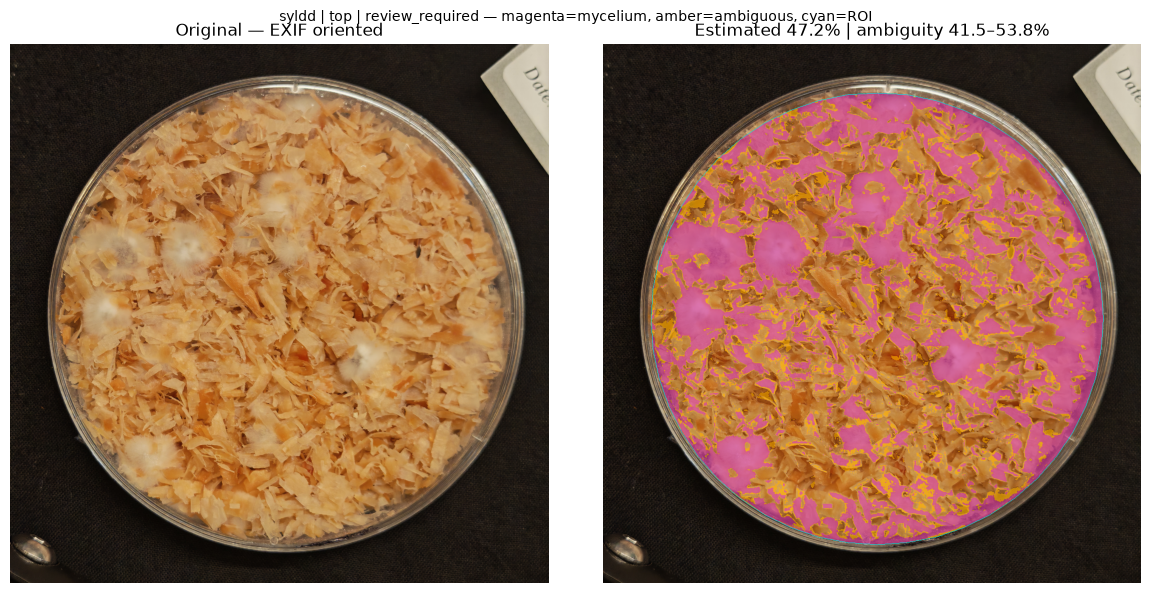

- Overlay not yet marked reviewed.


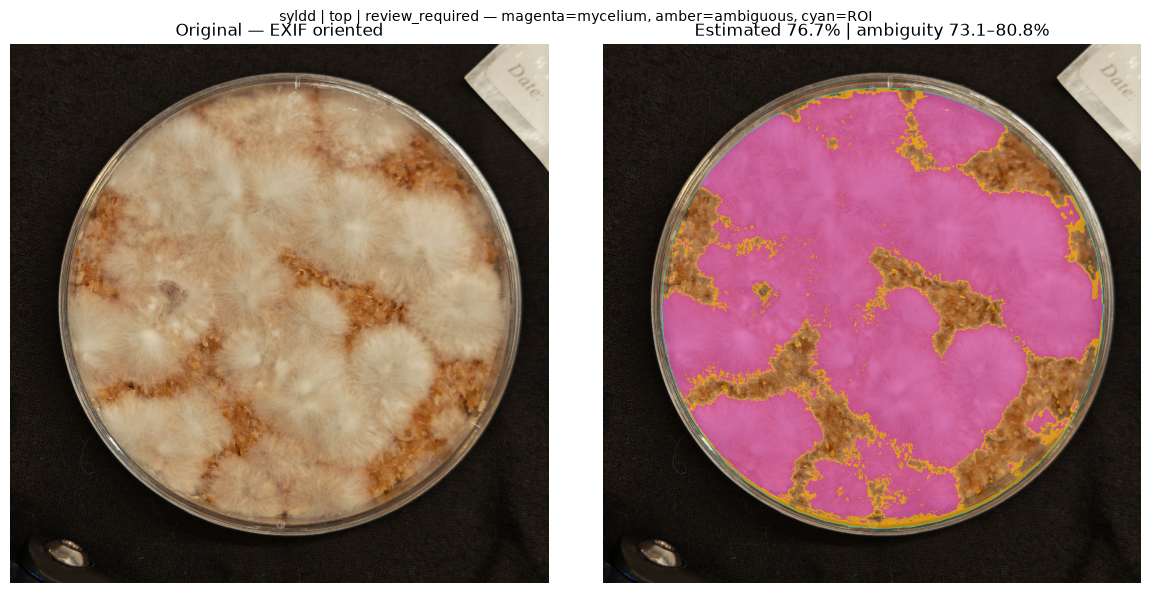

- Overlay not yet marked reviewed.
Forecast-ready: 0


In [5]:
results=[];errors=[]
for index,record in enumerate(records):
    try:results.append(analyse_record(record,index))
    except (ValueError,KeyError,OSError,TypeError) as exc:errors.append({'index':index,'image_path':str(record.get('image_path','')),'error':str(exc)})
enforce_unique_measurements(results)
summary=pd.DataFrame([{k:v for k,v in item['entry'].items() if k not in ['quality_metrics','method_details','method_comparison_pct','notes','blocking_reasons']} for item in results])
if summary.empty:summary=pd.DataFrame(columns=['index','image_path','photo_id','batch_id','sample_id','view_id','day','coverage_pct','quality_ok','status'])
if not summary.empty:display(summary)
if errors:display(pd.DataFrame(errors))
figures={}
for item in results:
    e=item['entry'];fig,axes=plt.subplots(1,2,figsize=(12,6));axes[0].imshow(item['rgb']);axes[0].set_title('Original — EXIF oriented')
    if 'overlay' in item:
        axes[1].imshow(item['overlay']);axes[1].set_title(f"Estimated {e['coverage_pct']:.1f}% | ambiguity {e['coverage_lower_pct']:.1f}–{e['coverage_upper_pct']:.1f}%")
    else:axes[1].imshow(item['rgb']);axes[1].set_title('Boundary needed; no percentage calculated')
    for ax in axes:ax.axis('off')
    fig.suptitle(f"{e['batch_id']} | {e['view_id']} | {e['status']} — magenta=mycelium, amber=ambiguous, cyan=ROI",fontsize=10)
    fig.tight_layout();figures[e['index']]=fig;plt.show()
    for reason in e.get('blocking_reasons',e.get('notes',[])):print('- '+reason)
print('Forecast-ready:',sum(bool(item['entry'].get('quality_ok')) for item in results))

## 5. Offline annotation editor

Open the editor, choose photos and fill **2. Record observation** (batch, batch start date, sample, top/side/bottom, date). The date comes from the photo itself (EXIF, else the `IMG_YYYYMMDD_HHMMSS` file name); the day is worked out from date minus batch start date. A photo with no outline gets a guessed one: drag its points to fix it. Then click a few typical spots of mycelium and of bare substrate; the editor shows a **preview** of the result. If it is wrong, paint over it with the correction brush. Press **Save** (it writes `photo_annotations.json` to Downloads) and load that file through `ANNOTATION_JSON`.

The preview is quick and approximate: **this notebook gives the final percentage.** For photos already listed here the editor embeds oriented previews and original paths. New browser-selected photos supply file names only: set `IMAGE_ROOT` to their directory. The browser cannot disclose full filesystem paths. **I checked the result** means you inspected the notebook overlay; it is not set automatically. A photo that is in both `PHOTO_RECORDS` and the JSON (same file) is counted once, from the JSON.


In [6]:
EDITOR_HTML = r'''<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Photo coverage</title>
<style>
*{box-sizing:border-box}body{margin:0;background:#f3f5f3;color:#20372f;font:15px system-ui,sans-serif}
header{padding:20px 28px;background:#173b31;color:#fff}header h1{font-size:24px;margin:0 0 8px}header p{margin:0;color:#cde2d6;max-width:1000px}
.tips{max-width:1500px;margin:18px auto 0;padding:0 20px}.tips div{background:#fff4da;border:1px solid #e8d49b;border-radius:10px;padding:12px 16px;line-height:1.5}
main{max-width:1500px;margin:auto;padding:18px 20px 30px;display:grid;grid-template-columns:290px 1fr;gap:18px}
.panel{background:#fff;border:1px solid #d8e1da;border-radius:12px;padding:18px}
h2{font-size:17px;margin:0 0 12px}label{display:block;margin:10px 0 4px;font-weight:600}
input,select,button{font:inherit}
input[type=text],input[type=number],input[type=date],select{width:100%;padding:8px;border:1px solid #b4c6bb;border-radius:6px}
input[type=file]{width:100%}
button{padding:9px 12px;border-radius:7px;border:1px solid #9bb5a4;background:#f7faf8;color:#20372f;cursor:pointer}
button:hover{background:#dfebe3}button.primary{background:#28684f;color:#fff;border-color:#28684f}
button.active{background:#d2eee1;border-color:#27674f;box-shadow:inset 0 0 0 2px #27674f}
button.pink{border-color:#e114b9;background:#ffe9f9}button.pink.active{background:#ffc7f1;box-shadow:inset 0 0 0 2px #e114b9}
button.green{border-color:#1f9d63;background:#e3f8ec}button.green.active{background:#bdeed3;box-shadow:inset 0 0 0 2px #1f9d63}
.row{display:flex;gap:8px;flex-wrap:wrap;align-items:center}.row>*{flex:1}
.samples{display:grid;grid-template-columns:1fr 1fr;gap:12px;margin:12px 0}.samples button{width:100%}
.group{margin:12px 0}.group .gl{display:block;font-weight:600;margin-bottom:6px}
.brush{display:flex;flex-wrap:wrap;gap:8px;align-items:center}.brush label{margin:0;display:flex;gap:8px;align-items:center;font-weight:400}
canvas{display:block;max-width:100%;height:auto;margin:10px auto;cursor:crosshair;background:#e9edeb;border:1px solid #d1dcd5;touch-action:none}
.hint{font-size:13px;color:#52695b;line-height:1.5;margin:6px 0 0}
.check{display:flex;gap:8px;align-items:flex-start;font-size:14px;font-weight:400}.check input{margin-top:4px}
#status{margin:14px 0;background:#fff4da;border:1px solid #e8d49b;border-radius:10px;padding:14px 18px;line-height:1.4;font-size:19px;font-weight:700;min-height:56px}
.prevrow{display:flex;flex-wrap:wrap;align-items:center;justify-content:space-between;gap:10px 24px;margin:6px 0 0}.prevrow .check{margin:0;font-size:19px;font-weight:600;align-items:center}.prevrow .check input{width:24px;height:24px;margin:0}#pct{font-size:26px;font-weight:700;color:#173b31}.sampletext{font-size:15px;color:#33493f;margin:12px 0 6px;line-height:1.5}
.legend{display:flex;flex-wrap:wrap;gap:6px 18px;font-size:13px;color:#33493f;margin:4px 0 12px}
.legend i{display:inline-block;vertical-align:middle;margin-right:6px}
.sw-line{width:20px;height:0;border-top:3px solid}.sw-dot{width:11px;height:11px;border-radius:50%;border:1.5px solid #fff;box-shadow:0 0 0 1px #888}.sw-box{width:16px;height:12px;border-radius:2px}
details{margin:14px 0;border:1px solid #d8e1da;border-radius:8px;padding:10px 14px;background:#fafcfb}summary{cursor:pointer;font-weight:600}
.count{font-size:13px;color:#52695b}.space{margin-top:14px}
@media(max-width:850px){main{grid-template-columns:1fr}.samples{grid-template-columns:1fr}}
</style></head><body>
<header><h1>Photo coverage</h1><p>Outline the substrate and click a few example spots. Everything stays in this browser; no photo is uploaded. The notebook gives the final percentage.</p></header>
<div class="tips"><div><b>Photo tips:</b> Fill the frame with the substrate, or use a dark background. Keep the same distance each time. No flash, avoid glare.</div></div>
<main><aside class="panel">
<h2>1. Choose photos</h2><input id="files" type="file" accept="image/*" multiple>
<label for="photos">Selected photo</label><select id="photos"></select>
<div class="row space"><button id="previous">Previous</button><button id="next">Next</button></div>
<p id="filename" class="count">No photo selected</p>
<h2 class="space">2. Record observation</h2>
<label for="batch">Batch ID</label><input id="batch" type="text">
<label for="start">Batch start date</label><input id="start" type="date">
<label for="sample">Sample ID</label><input id="sample" type="text" placeholder="e.g. SYLDD-WS10-D1">
<label for="view">Surface / view</label><select id="view"><option value="top">Top</option><option value="side">Side</option><option value="bottom">Bottom</option></select>
<label for="date">Date</label><input id="date" type="date">
</aside>
<section class="panel">
<h2>3. Trace and label the substrate</h2>
<label class="check"><input id="whole" type="checkbox"><span>Substrate fills the whole photo</span></label>
<div class="group"><span class="gl">Outline</span><div class="row"><button data-tool="roi" id="redraw">Redraw outline</button><button id="guess">Guess outline again</button><button id="finish">Finish outline (Enter)</button><button id="clearPending">Cancel</button></div></div>
<p class="sampletext">Click a few typical spots for both mycelium and substrate. The program finds every part that looks similar.</p>
<div class="samples">
<div><button class="pink" data-tool="mycelium_seed">Click on mycelium</button></div>
<div><button class="green" data-tool="substrate_seed">Click on bare substrate</button></div>
</div>
<div class="group"><span class="gl">Correction brush</span><div class="brush"><button class="pink" data-tool="paint_mycelium">Paint mycelium</button><button class="green" data-tool="paint_substrate">Paint bare substrate</button><label>Size <input id="brush" type="range" min="1" max="20" value="4"></label></div><p class="hint">Use the brush when the result is wrong.</p></div>
<div class="row"><button id="undo">Undo</button><button id="clearSeeds">Clear clicks</button><button id="clearStrokes">Clear brush strokes</button></div>
<div id="status">Choose a photo to begin.</div>
<div class="prevrow"><label class="check"><input id="showPrev" type="checkbox" checked><span>Show the preview colours</span></label><div id="pct"></div></div>
<canvas id="canvas" width="900" height="520"></canvas>
<div class="legend"><span><i class="sw-line" style="border-color:#00d9df"></i>cyan = outline</span><span><i class="sw-dot" style="background:#ff21ce"></i>pink dot = mycelium sample</span><span><i class="sw-dot" style="background:#00f594"></i>green dot = bare substrate sample</span><span><i class="sw-box" style="background:#e114b9"></i>magenta = counted as mycelium</span><span><i class="sw-box" style="background:#ffb000"></i>amber = not sure</span></div>
<details id="advanced"><summary>Advanced</summary>
<label for="method">Method</label><select id="method"><option value="auto">Auto: samples, otherwise clustering</option><option value="seeded">Samples only (both kinds required)</option><option value="cluster">Colour + texture clustering</option><option value="hsv">HSV comparison baseline</option><option value="manual">Manual correction polygons</option></select>
<label for="radius">Sample size (% of the short side)</label><input id="radius" type="number" min="0.1" max="10" step="0.1" value="1.5">
<div class="group"><span class="gl">Uncertain areas and background holes</span><div class="row"><button data-tool="uncertain">Mark uncertain area</button><button data-tool="background">Exclude background hole</button></div></div>
<div class="group"><span class="gl">Old correction polygons</span><div class="row"><button data-tool="mycelium">Correct: mycelium polygon</button><button data-tool="substrate">Correct: bare substrate polygon</button><button id="clearPolys">Clear polygons</button></div></div>
<label class="check"><input id="selected" type="checkbox" checked><span>Use this photo in the forecast (one per sample, view and day).</span></label>
</details>
<h2 class="space">4. Save</h2>
<label class="check"><input id="reviewed" type="checkbox"><span>I checked the result</span></label>
<div class="row space"><button id="download" class="primary">Save</button></div>
<label for="annotationFile">Open a saved file</label><input id="annotationFile" type="file" accept=".json,application/json">
</section></main>
<script>
'use strict';
const initial=__INITIAL_PREVIEWS__;
const BATCH_STARTS=__BATCH_STARTS__;
const DEFAULT_BATCH=__DEFAULT_BATCH__;
const VIEWS=['top','side','bottom'];
const $=id=>document.getElementById(id);const canvas=$('canvas'),ctx=canvas.getContext('2d');
let photos=[],index=-1,tool='mycelium_seed',pending=[],undoStack=[],drag=null,stroke=null,down=null;
const carry={batch_id:DEFAULT_BATCH,batch_start_date:BATCH_STARTS[DEFAULT_BATCH]||''};
const scratch=document.createElement('canvas'),sctx=scratch.getContext('2d',{willReadFrequently:true});
function clone(x){return JSON.parse(JSON.stringify(x));}
function clamp01(v){return Math.min(1,Math.max(0,v));}
function baseName(s){return String(s||'').split(/[\\/]/).pop();}
function base(record={}){const r={image_path:'',photo_id:'',batch_id:carry.batch_id,batch_start_date:'',sample_id:'',view:'top',method:'auto',seeds:[],strokes:[],corrections:[],background_exclusions:[],reviewed:false,selected_for_forecast:true,full_frame_substrate_confirmed:false,...record};if(!r.batch_start_date)r.batch_start_date=BATCH_STARTS[r.batch_id]||carry.batch_start_date||'';return r;}
function current(){return index>=0?photos[index]:null;}
function message(s){$('status').textContent=s;}
function pushUndo(){if(current())undoStack.push(clone(current().record));}
function changed(){const p=current();if(p){p.record.reviewed=false;$('reviewed').checked=false;refreshPreview();}draw();}

/* ---- photo date: EXIF DateTimeOriginal, else IMG_YYYYMMDD_HHMMSS file name ---- */
function exifDate(buf){try{const v=new DataView(buf);if(v.getUint16(0)!==0xFFD8)return '';let o=2;
while(o+4<v.byteLength){const m=v.getUint16(o);if(m===0xFFDA||(m&0xFF00)!==0xFF00)break;const len=v.getUint16(o+2);
if(m===0xFFE1&&v.getUint32(o+4)===0x45786966){const t=o+10,le=v.getUint16(t)===0x4949;const u16=a=>v.getUint16(a,le),u32=a=>v.getUint32(a,le);
const find=(ifd,tag)=>{const n=u16(t+ifd);for(let k=0;k<n;k++){const e=t+ifd+2+12*k;if(u16(e)===tag)return e;}return -1;};
const ptr=find(u32(t+4),0x8769);if(ptr<0)return '';const q=find(u32(ptr+8),0x9003);if(q<0)return '';
const off=t+u32(q+8);let s='';for(let i=0;i<19;i++)s+=String.fromCharCode(v.getUint8(off+i));
const d=s.match(/^(\d{4}):(\d{2}):(\d{2})/);return d&&d[1]!=='0000'?d[1]+'-'+d[2]+'-'+d[3]:'';}
o+=2+len;}}catch(e){}return '';}
function nameDate(name){const d=String(name).match(/(\d{4})(\d{2})(\d{2})_\d{6}/);return d&&+d[2]>=1&&+d[2]<=12&&+d[3]>=1&&+d[3]<=31?d[1]+'-'+d[2]+'-'+d[3]:'';}
function photoDate(buf,name){return exifDate(buf)||nameDate(name);}

/* ---- geometry ---- */
function inside(points,x,y){let c=false;for(let i=0,j=points.length-1;i<points.length;j=i++){const [xi,yi]=points[i],[xj,yj]=points[j];if((yi>y)!==(yj>y)&&x<(xj-xi)*(y-yi)/(yj-yi)+xi)c=!c;}return c;}
function orient(a,b,c){return (b[0]-a[0])*(c[1]-a[1])-(b[1]-a[1])*(c[0]-a[0]);}
function selfCrosses(pts){const n=pts.length;for(let i=0;i<n;i++)for(let j=i+1;j<n;j++){if((j-i)%n===1||(j-i)%n===n-1)continue;const a=pts[i],b=pts[(i+1)%n],c=pts[j],d=pts[(j+1)%n];if(orient(a,b,c)*orient(a,b,d)<0&&orient(c,d,a)*orient(c,d,b)<0)return true;}return false;}
function hull(pts){pts=pts.slice().sort((a,b)=>a[0]-b[0]||a[1]-b[1]);const lo=[];for(const p of pts){while(lo.length>=2&&orient(lo[lo.length-2],lo[lo.length-1],p)<=0)lo.pop();lo.push(p);}const up=[];for(let i=pts.length-1;i>=0;i--){const p=pts[i];while(up.length>=2&&orient(up[up.length-2],up[up.length-1],p)<=0)up.pop();up.push(p);}lo.pop();up.pop();return lo.concat(up);}
function segDist(p,a,b){const dx=b[0]-a[0],dy=b[1]-a[1],L=dx*dx+dy*dy;let t=L?((p[0]-a[0])*dx+(p[1]-a[1])*dy)/L:0;t=Math.max(0,Math.min(1,t));return Math.hypot(p[0]-a[0]-t*dx,p[1]-a[1]-t*dy);}
function dp(chain,eps){if(chain.length<3)return chain;let best=-1,bi=0;for(let i=1;i<chain.length-1;i++){const d=segDist(chain[i],chain[0],chain[chain.length-1]);if(d>best){best=d;bi=i;}}if(best<=eps)return [chain[0],chain[chain.length-1]];const l=dp(chain.slice(0,bi+1),eps),r=dp(chain.slice(bi),eps);return l.slice(0,-1).concat(r);}
function simplifyRing(ring,eps){let far=0,fd=-1;for(let i=1;i<ring.length;i++){const d=Math.hypot(ring[i][0]-ring[0][0],ring[i][1]-ring[0][1]);if(d>fd){fd=d;far=i;}}const a=dp(ring.slice(0,far+1),eps),b=dp(ring.slice(far).concat([ring[0]]),eps);return a.slice(0,-1).concat(b.slice(0,-1));}
function toTarget(ring,target){if(ring.length<=target)return ring;let lo=0,hi=.5,best=simplifyRing(ring,hi);for(let k=0;k<24;k++){const mid=(lo+hi)/2,s=simplifyRing(ring,mid);if(s.length>target)lo=mid;else{hi=mid;best=s;}}return best.length>=3?best:ring.slice(0,3);}

/* ---- automatic outline: brighter substrate on a darker background ---- */
function outlineGuess(img){
const sc=Math.min(1,200/Math.max(img.naturalWidth,img.naturalHeight)),w=Math.max(8,Math.round(img.naturalWidth*sc)),h=Math.max(8,Math.round(img.naturalHeight*sc));
scratch.width=w;scratch.height=h;sctx.drawImage(img,0,0,w,h);const d=sctx.getImageData(0,0,w,h).data,N=w*h,g=new Uint8Array(N),hist=new Array(256).fill(0);
for(let i=0;i<N;i++){const v=Math.round(.2126*d[4*i]+.7152*d[4*i+1]+.0722*d[4*i+2]);g[i]=v;hist[v]++;}
let sum=0;for(let t=0;t<256;t++)sum+=t*hist[t];let wb=0,sb=0,best=-1,thr=128;
for(let t=0;t<256;t++){wb+=hist[t];if(!wb)continue;const wf=N-wb;if(!wf)break;sb+=t*hist[t];const mb=sb/wb,mf=(sum-sb)/wf,bt=wb*wf*(mb-mf)*(mb-mf);if(bt>best){best=bt;thr=t;}}
const lab=new Int32Array(N),stack=new Int32Array(N);let nl=0,bestLab=0,bestN=0;
for(let s=0;s<N;s++){if(g[s]<=thr||lab[s])continue;nl++;let sp=0,cnt=0;stack[sp++]=s;lab[s]=nl;
while(sp){const q=stack[--sp];cnt++;const x=q%w,y=(q-x)/w;
if(x>0&&g[q-1]>thr&&!lab[q-1]){lab[q-1]=nl;stack[sp++]=q-1;}
if(x<w-1&&g[q+1]>thr&&!lab[q+1]){lab[q+1]=nl;stack[sp++]=q+1;}
if(y>0&&g[q-w]>thr&&!lab[q-w]){lab[q-w]=nl;stack[sp++]=q-w;}
if(y<h-1&&g[q+w]>thr&&!lab[q+w]){lab[q+w]=nl;stack[sp++]=q+w;}}
if(cnt>bestN){bestN=cnt;bestLab=nl;}}
if(bestN<.02*N)return null;
const pts=[];for(let y=0;y<h;y++)for(let x=0;x<w;x++){const q=y*w+x;if(lab[q]!==bestLab)continue;
if(x===0||y===0||x===w-1||y===h-1||lab[q-1]!==bestLab||lab[q+1]!==bestLab||lab[q-w]!==bestLab||lab[q+w]!==bestLab){pts.push([x/w,y/h],[(x+1)/w,y/h],[x/w,(y+1)/h],[(x+1)/w,(y+1)/h]);}}
const ring=toTarget(hull(pts),24);return ring.length>=3?ring.map(([x,y])=>[clamp01(x),clamp01(y)]):null;}
function guessOutline(p){const pts=outlineGuess(p.image);if(!pts)return false;p.record.roi={kind:'polygon',points:pts};return true;}

/* ---- live preview: the notebook's example idea (nearest colour/texture to the samples, inside the outline) ---- */
function boxMean(a,w,h,r){const I=new Float64Array((w+1)*(h+1));for(let y=0;y<h;y++){let row=0;for(let x=0;x<w;x++){row+=a[y*w+x];I[(y+1)*(w+1)+x+1]=I[y*(w+1)+x+1]+row;}}
const out=new Float32Array(w*h);for(let y=0;y<h;y++){const y0=Math.max(0,y-r),y1=Math.min(h-1,y+r);for(let x=0;x<w;x++){const x0=Math.max(0,x-r),x1=Math.min(w-1,x+r);out[y*w+x]=(I[(y1+1)*(w+1)+x1+1]-I[y0*(w+1)+x1+1]-I[(y1+1)*(w+1)+x0]+I[y0*(w+1)+x0])/((x1-x0+1)*(y1-y0+1));}}return out;}
function ensureFeatures(p){if(p.feat)return p.feat;const img=p.image,sc=Math.min(1,480/Math.max(img.naturalWidth,img.naturalHeight)),w=Math.max(8,Math.round(img.naturalWidth*sc)),h=Math.max(8,Math.round(img.naturalHeight*sc));
scratch.width=w;scratch.height=h;sctx.drawImage(img,0,0,w,h);const d=sctx.getImageData(0,0,w,h).data,N=w*h,F=new Float32Array(N*6),gray=new Float32Array(N),gray2=new Float32Array(N);
const lin=v=>{v/=255;return v<=.04045?v/12.92:Math.pow((v+.055)/1.055,2.4);},f=t=>t>.008856451679?Math.cbrt(t):t/(3*(6/29)**2)+4/29;
for(let i=0;i<N;i++){const R=d[4*i],G=d[4*i+1],B=d[4*i+2],r=lin(R),gg=lin(G),b=lin(B);
const X=.4124564*r+.3575761*gg+.1804375*b,Y=.2126729*r+.7151522*gg+.072175*b,Z=.0193339*r+.119192*gg+.9503041*b;
const fx=f(X/.95047),fy=f(Y),fz=f(Z/1.08883);F[6*i]=(116*fy-16)/100;F[6*i+1]=500*(fx-fy)/128*.7;F[6*i+2]=200*(fy-fz)/128*.7;
const gv=(.2126*R+.7152*G+.0722*B)/255;gray[i]=gv;gray2[i]=gv*gv;const mx=Math.max(R,G,B)/255,mn=Math.min(R,G,B)/255;F[6*i+5]=(mx>0?(mx-mn)/mx:0)*.25;}
const m=boxMean(gray,w,h,2),m2=boxMean(gray2,w,h,2);
for(let y=0;y<h;y++)for(let x=0;x<w;x++){const i=y*w+x,tex=Math.sqrt(Math.max(0,m2[i]-m[i]*m[i])),gx=(gray[y*w+Math.min(w-1,x+1)]-gray[y*w+Math.max(0,x-1)])/2,gy=(gray[Math.min(h-1,y+1)*w+x]-gray[Math.max(0,y-1)*w+x])/2;
F[6*i+3]=Math.min(2,Math.max(0,tex/.15))*.35;F[6*i+4]=Math.min(2,Math.max(0,Math.hypot(gx,gy)/.2))*.2;}
p.feat={w,h,F};return p.feat;}
function pathPoly(c,points,w,h){c.beginPath();points.forEach(([x,y],i)=>i?c.lineTo(x*w,y*h):c.moveTo(x*w,y*h));c.closePath();}
function strokePath(c,s,w,h,sizePx){c.lineCap='round';c.lineJoin='round';c.lineWidth=sizePx;const pts=s.points;for(const [x,y] of pts){c.beginPath();c.arc(x*w,y*h,sizePx/2,0,Math.PI*2);c.fill();}
if(pts.length>1){c.beginPath();pts.forEach(([x,y],i)=>i?c.lineTo(x*w,y*h):c.moveTo(x*w,y*h));c.stroke();}}
function raster(w,h,fn){scratch.width=w;scratch.height=h;sctx.clearRect(0,0,w,h);sctx.fillStyle='#000';sctx.strokeStyle='#000';fn(sctx);const a=sctx.getImageData(0,0,w,h).data,out=new Uint8Array(w*h);for(let i=0;i<out.length;i++)out[i]=a[4*i+3]>127?1:0;return out;}
function computePreview(p){
const r=p.record;if(!p.image)return null;const {w,h,F}=ensureFeatures(p),N=w*h;let roi;
if(r.full_frame_substrate_confirmed)roi=new Uint8Array(N).fill(1);else if(r.roi?.points?.length>=3)roi=raster(w,h,c=>{pathPoly(c,r.roi.points,w,h);c.fill();});else return {status:'Draw the outline to see a preview.'};
for(const pts of r.background_exclusions||[]){const hole=raster(w,h,c=>{pathPoly(c,pts,w,h);c.fill();});for(let i=0;i<N;i++)if(hole[i])roi[i]=0;}
let nroi=0;for(let i=0;i<N;i++)nroi+=roi[i];if(!nroi)return {status:'The outline is empty.'};
const cls=new Int8Array(N).fill(-1);
for(const s of r.seeds||[]){const rad=Math.max(1,(s.radius||.015)*Math.min(h,w)),cx=s.x*(w-1),cy=s.y*(h-1),k=s.label==='mycelium'?0:1;
for(let y=Math.max(0,Math.floor(cy-rad));y<=Math.min(h-1,Math.ceil(cy+rad));y++)for(let x=Math.max(0,Math.floor(cx-rad));x<=Math.min(w-1,Math.ceil(cx+rad));x++){if((x-cx)**2+(y-cy)**2<=rad*rad&&roi[y*w+x]&&cls[y*w+x]<0)cls[y*w+x]=k;}}
const cnt=[0,0],mean=[new Float64Array(6),new Float64Array(6)],v2=[new Float64Array(6),new Float64Array(6)];
for(let i=0;i<N;i++){const k=cls[i];if(k<0)continue;cnt[k]++;for(let j=0;j<6;j++){const v=F[6*i+j];mean[k][j]+=v;v2[k][j]+=v*v;}}
if(!cnt[0]||!cnt[1])return {status:'Click on mycelium and on bare substrate to see a preview.'};
const sc=new Float64Array(6);let sep=0;
for(let j=0;j<6;j++){mean[0][j]/=cnt[0];mean[1][j]/=cnt[1];const va=v2[0][j]/cnt[0]-mean[0][j]**2,vb=v2[1][j]/cnt[1]-mean[1][j]**2;sc[j]=Math.sqrt((va+vb)/2+.03**2);sep+=((mean[0][j]-mean[1][j])/sc[j])**2;}
sep=Math.sqrt(sep);const mask=new Uint8Array(N),unc=new Uint8Array(N);
for(let i=0;i<N;i++){if(!roi[i])continue;let d0=0,d1=0;for(let j=0;j<6;j++){const v=F[6*i+j];d0+=((v-mean[0][j])/sc[j])**2;d1+=((v-mean[1][j])/sc[j])**2;}
mask[i]=d0<=d1?1:0;unc[i]=(Math.abs(d0-d1)/(d0+d1+1e-8)<.18||Math.min(d0,d1)>25||sep<1)?1:0;}
for(const c of r.corrections||[]){const reg=raster(w,h,cc=>{pathPoly(cc,c.points,w,h);cc.fill();});for(let i=0;i<N;i++){if(!reg[i]||!roi[i])continue;if(c.label==='mycelium'){mask[i]=1;unc[i]=0;}else if(c.label==='substrate'){mask[i]=0;unc[i]=0;}else unc[i]=1;}}
for(const s of r.strokes||[]){const reg=raster(w,h,cc=>strokePath(cc,s,w,h,s.size*Math.min(w,h)));for(let i=0;i<N;i++){if(!reg[i]||!roi[i])continue;if(s.label==='mycelium'){mask[i]=1;unc[i]=0;}else{mask[i]=0;unc[i]=0;}}}
let nm=0;const ov=document.createElement('canvas');ov.width=w;ov.height=h;const octx=ov.getContext('2d'),img=octx.createImageData(w,h);
for(let i=0;i<N;i++){if(!roi[i])continue;if(mask[i])nm++;if(unc[i]){img.data.set([255,176,0,140],4*i);}else if(mask[i]){img.data.set([225,20,185,115],4*i);}}
octx.putImageData(img,0,0);return {pct:100*nm/nroi,overlay:ov};}
function refreshPreview(){const p=current();if(p?.image)p.prev=computePreview(p);}

/* ---- drawing ---- */
function polygon(points,colour,fill=true,close=true,dots=true){if(!points?.length)return;ctx.beginPath();points.forEach(([x,y],i)=>{i?ctx.lineTo(x*canvas.width,y*canvas.height):ctx.moveTo(x*canvas.width,y*canvas.height);});if(close)ctx.closePath();ctx.strokeStyle=colour;ctx.lineWidth=2;if(fill&&close){ctx.globalAlpha=.17;ctx.fillStyle=colour;ctx.fill();ctx.globalAlpha=1;}ctx.stroke();if(dots)for(const [x,y] of points){ctx.beginPath();ctx.arc(x*canvas.width,y*canvas.height,3,0,Math.PI*2);ctx.fillStyle=colour;ctx.fill();}}
function setPct(p){$('pct').textContent=p?.prev&&p.prev.pct!==undefined?p.prev.pct.toFixed(1)+'% colonised (preview)':'% colonised (preview): –';}
function draw(){ctx.clearRect(0,0,canvas.width,canvas.height);const p=current();setPct(p);
if(!p?.image){ctx.fillStyle='#52695b';ctx.font='20px system-ui';ctx.fillText('Choose a substrate photo',35,65);return;}
const W=canvas.width,H=canvas.height,r=p.record;ctx.drawImage(p.image,0,0,W,H);
if($('showPrev').checked&&p.prev?.overlay)ctx.drawImage(p.prev.overlay,0,0,W,H);
for(const points of r.background_exclusions||[])polygon(points,'#777');
for(const c of r.corrections||[])polygon(c.points,c.label==='mycelium'?'#e114b9':c.label==='substrate'?'#20a56a':'#ffb000');
if(r.full_frame_substrate_confirmed)polygon([[0,0],[1,0],[1,1],[0,1]],'#00d9df',false,true,false);
if(r.roi?.points){polygon(r.roi.points,'#00d9df',false,true,false);for(const [x,y] of r.roi.points){ctx.beginPath();ctx.arc(x*W,y*H,6,0,Math.PI*2);ctx.fillStyle='#fff';ctx.fill();ctx.strokeStyle='#00a9ae';ctx.lineWidth=2;ctx.stroke();}}
ctx.globalAlpha=.5;for(const s of r.strokes||[]){ctx.fillStyle=ctx.strokeStyle=s.label==='mycelium'?'#ff21ce':'#00f594';strokePath(ctx,s,W,H,s.size*Math.min(W,H));}ctx.globalAlpha=1;
for(const s of r.seeds||[]){ctx.beginPath();ctx.arc(s.x*W,s.y*H,5,0,Math.PI*2);ctx.fillStyle=s.label==='mycelium'?'#ff21ce':'#00f594';ctx.fill();ctx.strokeStyle='#fff';ctx.lineWidth=1.5;ctx.stroke();}
polygon(pending,'#fff',false,false);
}

/* ---- fields and photo list ---- */
function readFields(){const p=current();if(!p)return;const r=p.record;
r.batch_id=$('batch').value.trim();r.batch_start_date=$('start').value;r.sample_id=$('sample').value.trim();r.view=$('view').value;
if($('date').value==='')delete r.date;else{r.date=$('date').value;delete r.day;}
r.method=$('method').value;r.reviewed=$('reviewed').checked;r.selected_for_forecast=$('selected').checked;r.full_frame_substrate_confirmed=$('whole').checked;
if(r.batch_id)carry.batch_id=r.batch_id;carry.batch_start_date=r.batch_start_date;}
function refreshList(){$('photos').replaceChildren();photos.forEach((p,i)=>{const o=document.createElement('option');o.value=String(i);o.textContent=(i+1)+'. '+baseName(p.record.image_path);$('photos').appendChild(o);});$('photos').value=String(index);}
function setTool(t,text){tool=t;for(const b of document.querySelectorAll('button[data-tool]'))b.classList.toggle('active',b.dataset.tool===t);if(text)message(text);}
const TOOL_TEXT={mycelium_seed:'Click a few typical mycelium spots inside the outline.',substrate_seed:'Click a few typical bare-substrate spots inside the outline.',paint_mycelium:'Paint over mycelium that the preview missed.',paint_substrate:'Paint over bare substrate that the preview counted as mycelium.',roi:'Click around the edge of the substrate, then press Finish outline.',uncertain:'Click corners, then press Finish outline (Enter) to mark an unsure area.',background:'Click corners around a hole that is not substrate, then press Finish.',mycelium:'Click corners around mycelium, then press Finish.',substrate:'Click corners around bare substrate, then press Finish.'};
function show(i,preserveUndo=false){readFields();index=i;pending=[];stroke=null;drag=null;if(!preserveUndo)undoStack=[];const p=current();if(!p)return;const r=p.record;refreshList();
$('batch').value=r.batch_id||'';$('start').value=r.batch_start_date||'';$('sample').value=r.sample_id||'';$('view').value=VIEWS.includes(r.view)?r.view:'top';$('date').value=r.date||'';
$('method').value=r.method||'auto';$('whole').checked=!!r.full_frame_substrate_confirmed;$('reviewed').checked=!!r.reviewed;$('selected').checked=r.selected_for_forecast!==false;$('filename').textContent=baseName(r.image_path);
if(p.image){const sc=Math.min(1,1000/Math.max(p.image.naturalWidth,p.image.naturalHeight));canvas.width=Math.round(p.image.naturalWidth*sc);canvas.height=Math.round(p.image.naturalHeight*sc);
let guessed=false;if(!r.roi&&!r.roi_mask_path&&!r.full_frame_substrate_confirmed&&!p.noGuess)guessed=guessOutline(p);
refreshPreview();message(guessed?'Outline guessed from the photo. Drag the white points to fix it, then click on mycelium and on bare substrate.':TOOL_TEXT[tool]||'');}
else message('Choose the matching photo file to display this saved annotation.');
draw();}
async function decoded(src){return new Promise((resolve,reject)=>{const image=new Image();image.onload=()=>resolve(image);image.onerror=()=>reject(new Error('Cannot decode image'));image.src=src;});}
const hex=buf=>Array.from(new Uint8Array(buf),x=>x.toString(16).padStart(2,'0')).join('');
$('files').addEventListener('change',async e=>{readFields();
for(const file of e.target.files){try{const url=URL.createObjectURL(file);const image=await decoded(url);URL.revokeObjectURL(url);const buf=await file.arrayBuffer();let hash;try{hash=hex(await crypto.subtle.digest('SHA-256',buf));}catch(err){}
const date=photoDate(buf,file.name),existing=photos.find(p=>baseName(p.record.image_path)===file.name);
if(existing){existing.image=image;existing.feat=null;if(hash)existing.record.image_sha256=hash;if(!existing.record.date&&date)existing.record.date=date;}
else photos.push({record:base({image_path:file.name,photo_id:file.name,...(hash?{image_sha256:hash}:{}),...(date?{date}:{})}),image});}catch(error){message(file.name+': '+error.message);}}
if(photos.length)show(photos.length-1);e.target.value='';});
$('photos').addEventListener('change',e=>show(Number(e.target.value)));$('previous').onclick=()=>{if(index>0)show(index-1);};$('next').onclick=()=>{if(index+1<photos.length)show(index+1);};

/* ---- tools ---- */
document.addEventListener('click',e=>{const b=e.target.closest('button[data-tool]');if(!b)return;b.blur();const p=current();
if(pending.length){message('Finish or cancel the unfinished shape first.');return;}
if(b.dataset.tool==='roi'&&p){pushUndo();delete p.record.roi;delete p.record.roi_mask_path;p.record.full_frame_substrate_confirmed=false;p.noGuess=true;$('whole').checked=false;changed();}
setTool(b.dataset.tool,TOOL_TEXT[b.dataset.tool]);});
$('guess').onclick=()=>{const p=current();if(!p?.image)return;pushUndo();delete p.record.roi;p.record.full_frame_substrate_confirmed=false;$('whole').checked=false;p.noGuess=false;if(guessOutline(p)){changed();message('Outline guessed again. Drag the white points to fix it.');}else{changed();message('No clear substrate found. Use Redraw outline.');}};
function hitHandle(p,e){const pts=p.record.roi?.points;if(!pts)return -1;const rect=canvas.getBoundingClientRect();let best=-1,bd=14;pts.forEach(([x,y],i)=>{const d=Math.hypot(rect.left+x*rect.width-e.clientX,rect.top+y*rect.height-e.clientY);if(d<bd){bd=d;best=i;}});return best;}
function norm(e){const rect=canvas.getBoundingClientRect();return [clamp01((e.clientX-rect.left)/rect.width),clamp01((e.clientY-rect.top)/rect.height)];}
canvas.addEventListener('pointerdown',e=>{const p=current();if(!p?.image)return;e.preventDefault();canvas.setPointerCapture(e.pointerId);const [x,y]=norm(e),paint=tool.startsWith('paint_');
const hit=(!pending.length&&!paint)?hitHandle(p,e):-1;
if(hit>=0){pushUndo();drag={i:hit};return;}
if(paint){pushUndo();stroke={label:tool==='paint_mycelium'?'mycelium':'substrate',size:Number($('brush').value)/100,points:[[x,y]]};p.record.strokes.push(stroke);draw();return;}
down=[x,y];});
canvas.addEventListener('pointermove',e=>{const p=current();if(!p?.image)return;const [x,y]=norm(e);
if(drag){p.record.roi.points[drag.i]=[x,y];refreshPreview();draw();}
else if(stroke){const last=stroke.points[stroke.points.length-1];if(Math.hypot(x-last[0],y-last[1])>.004){stroke.points.push([x,y]);draw();}}});
canvas.addEventListener('pointerup',e=>{const p=current();if(!p?.image)return;const [x,y]=norm(e);
if(drag){drag=null;if(selfCrosses(p.record.roi.points)){p.record=undoStack.pop();const i=index;index=-1;show(i,true);message('That point would make the outline cross itself, so it was put back.');return;}changed();return;}
if(stroke){stroke=null;changed();return;}
if(down){down=null;click(x,y);}});
function click(x,y){const p=current();if(!p)return;const r=p.record;
if(tool.endsWith('_seed')){if(!r.full_frame_substrate_confirmed&&!r.roi?.points){message('Draw the outline first (Redraw outline), or tick "Substrate fills the whole photo".');return;}
if(!r.full_frame_substrate_confirmed&&!inside(r.roi.points,x,y)){message('That spot is outside the outline. Click inside it.');return;}
pushUndo();r.seeds.push({label:tool==='mycelium_seed'?'mycelium':'substrate',x,y,radius:Math.min(.1,Math.max(.001,Number($('radius').value)/100))});changed();const n=k=>r.seeds.filter(s=>s.label===k).length;message(!n('substrate')?'Now click on bare substrate to see the result.':!n('mycelium')?'Now click on mycelium to see the result.':'Spot added. A few spots of each kind work best.');}
else if(tool.startsWith('paint_')){}
else{pending.push([x,y]);draw();message(pending.length+' corners. Press Finish when the shape is complete.');}}
function finish(){const p=current();if(!p)return;if(pending.length<3){message('A shape needs at least three corners.');return;}if(selfCrosses(pending)){message('The edges cross each other. Cancel and try again.');return;}pushUndo();
if(tool==='roi'){p.record.roi={kind:'polygon',points:clone(pending)};delete p.record.roi_mask_path;p.record.full_frame_substrate_confirmed=false;$('whole').checked=false;pending=[];changed();setTool('mycelium_seed','Outline saved. Now click on mycelium and on bare substrate.');return;}
if(tool==='background')p.record.background_exclusions.push(clone(pending));else if(['mycelium','substrate','uncertain'].includes(tool))p.record.corrections.push({label:tool,points:clone(pending)});
pending=[];changed();message('Shape saved.');}
$('finish').onclick=finish;document.addEventListener('keydown',e=>{if(e.key==='Enter'&&!['INPUT','SELECT','TEXTAREA'].includes(e.target.tagName)){e.preventDefault();finish();}});
$('clearPending').onclick=()=>{pending=[];draw();};
$('undo').onclick=()=>{if(pending.length){pending.pop();draw();}else if(undoStack.length&&current()){current().record=undoStack.pop();const i=index;index=-1;show(i,true);}};
$('clearSeeds').onclick=()=>{if(current()){pushUndo();current().record.seeds=[];changed();}};
$('clearStrokes').onclick=()=>{if(current()){pushUndo();current().record.strokes=[];changed();}};
$('clearPolys').onclick=()=>{if(current()){pushUndo();current().record.corrections=[];current().record.background_exclusions=[];changed();}};
for(const id of ['batch','start','sample','view','date','selected','reviewed'])$(id).addEventListener('change',readFields);
$('batch').addEventListener('change',()=>{const s=BATCH_STARTS[$('batch').value.trim()];if(s&&!$('start').value){$('start').value=s;readFields();}});
$('showPrev').addEventListener('change',draw);
$('method').addEventListener('change',()=>{readFields();changed();});
$('whole').addEventListener('change',()=>{const p=current();if(!p)return;pushUndo();if($('whole').checked){delete p.record.roi;delete p.record.roi_mask_path;}readFields();if(!$('whole').checked&&p.image&&!p.record.roi){p.noGuess=false;guessOutline(p);}changed();});

/* ---- save and reload ---- */
$('download').onclick=()=>{readFields();if(!photos.length){message('Choose at least one photo before saving.');return;}if(pending.length){message('Finish or cancel the unfinished shape first.');return;}
const doc={schema_version:1,coordinate_system:'normalized EXIF-oriented image',photos:photos.map(p=>clone(p.record))};const a=document.createElement('a');a.href=URL.createObjectURL(new Blob([JSON.stringify(doc,null,2)],{type:'application/json'}));a.download='photo_annotations.json';a.click();setTimeout(()=>URL.revokeObjectURL(a.href),1000);message('Saved to Downloads as photo_annotations.json.');};
$('annotationFile').addEventListener('change',async e=>{const file=e.target.files[0];if(!file)return;try{const doc=JSON.parse(await file.text());if(doc.schema_version!==1||!Array.isArray(doc.photos))throw new Error('Unsupported annotation file');readFields();
for(const record of doc.photos){const existing=photos.find(p=>p.record.image_path===record.image_path||baseName(p.record.image_path)===baseName(record.image_path));if(existing){existing.record=base(record);existing.prev=null;}else photos.push({record:base(record),image:null});}
if(photos.length){index=-1;show(0);}}catch(error){message('Import failed: '+error.message);}e.target.value='';});
(async()=>{setTool('mycelium_seed');for(const p of initial){try{photos.push({record:base(p.record),image:await decoded(p.image_data)});}catch(error){message(error.message);}}if(photos.length)show(0);else draw();})();
</script></body></html>
'''
editor_previews=[]
for item in results:
    buffer=io.BytesIO();Image.fromarray(item['rgb']).save(buffer,format='PNG')
    record=dict(item['record']);record['image_path']=item['entry']['image_path'];record['image_sha256']=item['entry']['image_sha256'];record['date']=record.get('date') or photo_date(item['entry']['image_path'])
    editor_previews.append({'record':record,'image_data':'data:image/png;base64,'+base64.b64encode(buffer.getvalue()).decode()})
def js_json(value):return json.dumps(value).replace('<','\\u003c')
editor_document=EDITOR_HTML.replace('__INITIAL_PREVIEWS__',js_json(editor_previews)).replace('__BATCH_STARTS__',js_json(BATCH_START_DATES)).replace('__DEFAULT_BATCH__',js_json(BATCH_DEFAULTS['batch_id']))

## 6. Software checks — artificial patterns, not biological results

Tests verify arithmetic, boundaries, corrections and units. Real d005/syldd photographs may be exercised separately without tuning global settings or inventing reference masks/accuracy.

In [7]:
checks=[]
def checked(name,condition):
    assert bool(condition),name
    checks.append(name)
def rejects(name,fn):
    try:fn()
    except (ValueError,KeyError,TypeError):checks.append(name)
    else:raise AssertionError(name)
full=np.ones((80,100),bool);half=np.zeros_like(full);half[:,:50]=True
checked('half ROI is 50 percent',coverage_statistics(half,np.zeros_like(full),full)['coverage_pct']==50.)
small=np.zeros_like(full);small[:,10:90]=True
checked('background excluded from denominator',coverage_statistics(half,np.zeros_like(full),small)['coverage_pct']==50.)
u=np.zeros_like(full);u[:,40:60]=True;stats=coverage_statistics(half,u,full)
checked('ambiguity retained in denominator',stats['coverage_lower_pct']==40. and stats['coverage_pct']==50. and stats['coverage_upper_pct']==60.)
rejects('empty ROI rejected',lambda:coverage_statistics(half,u,np.zeros_like(full)))
roi,message=substrate_mask({},full.shape,(100,80));checked('missing boundary yields no number',roi is None and message is not None)
roi,_=substrate_mask({'full_frame_substrate_confirmed':True},full.shape,(100,80));checked('explicit whole-frame mask works',roi.all())
rejects('conflicting ROI declarations rejected',lambda:substrate_mask({'full_frame_substrate_confirmed':True,'roi':{'kind':'polygon','points':[[0,0],[1,0],[1,1]]}},full.shape,(100,80)))
rejects('self-crossing polygon rejected',lambda:polygon_points([[0,0],[1,1],[0,1],[1,0]]))
rejects('out-of-range polygon rejected',lambda:polygon_points([[0,0],[2,0],[0,1]]))
checked('normalized full polygon covers frame',polygon_mask([[0,0],[1,0],[1,1],[0,1]],full.shape).all())
fixture=np.full((80,100,3),55,np.uint8);fixture[:,:50]=235;features,channels=image_features(fixture)
checked('features finite with six channels',features.shape==(80,100,6) and np.isfinite(features).all())
cm,cu,cd=cluster_candidate(features,full)
cs=coverage_statistics(cm,cu,full)
checked('cluster ambiguity envelope covers known software-pattern coverage',cs['coverage_lower_pct']<=50.<=cs['coverage_upper_pct'] and abs(cs['coverage_pct']-50.)<=5.)
uniform=np.full((80,100,3),220,np.uint8);uf,_=image_features(uniform);um,uu,ud=cluster_candidate(uf,full)
checked('uniform ROI is uncertain rather than falsely confident',uu.all())
seeds=[{'label':'mycelium','x':.2,'y':.5,'radius':.03},{'label':'substrate','x':.8,'y':.5,'radius':.03}]
m,u,d=seeded_candidate(features,full,seeds);checked('examples separate software pattern',np.mean(m==half)>.99)
rejects('contradictory seeds rejected',lambda:seed_masks([{'label':'mycelium','x':.5,'y':.5},{'label':'substrate','x':.5,'y':.5}],full))
rejects('both example labels required',lambda:seeded_candidate(features,full,seeds[:1]))
left=np.zeros_like(full);left[:,:40]=True;rejects('seed outside ROI rejected',lambda:seed_masks(seeds,left))
manual={'method':'manual','corrections':[{'label':'substrate','points':[[0,0],[1,0],[1,1],[0,1]]},{'label':'mycelium','points':[[0,0],[.49,0],[.49,1],[0,1]]}]}
m,u,*_=segment(fixture,full,manual);checked('manual corrections resolve exact half',np.array_equal(m,half) and not u.any())
manual['corrections'].append({'label':'uncertain','points':[[0,0],[1,0],[1,1],[0,1]]});m,u,*_=segment(fixture,full,manual)
checked('last uncertainty correction restores full ambiguity',u.all() and coverage_statistics(m,u,full)['coverage_upper_pct']==100.)
checked('review false remains false',boolean(False,'reviewed') is False)
rejects('text false cannot approve',lambda:boolean('False','reviewed'))
rejects('negative day rejected',lambda:observation_day({'day':-1}))
checked('day is date minus batch start date',observation_day({'date':'2026-10-12','batch_start_date':'2026-10-08'})[0]==4)
checked('time of day does not change the day',observation_day({'date':'2026-10-12T15:45:16','batch_start_date':'2026-10-08'})[0]==4)
rejects('date before batch start rejected',lambda:observation_day({'date':'2026-10-07','batch_start_date':'2026-10-08'}))
rejects('day and date that disagree rejected',lambda:observation_day({'day':5,'date':'2026-10-12','batch_start_date':'2026-10-08'}))
checked('known batch uses its start date',observation_day({'batch_id':'syldd','date':'2026-10-16'})[0]==8)
checked('file name gives the photo date',photo_date('IMG_20261012_154516_missing.jpg')=='2026-10-12' and photo_date('nodate.jpg')=='')
m0,*_=segment(fixture,full,{'seeds':seeds})
msub,usub,*_=segment(fixture,full,{'seeds':seeds,'strokes':[{'label':'substrate','size':.3,'points':[[.25,.5]]}]})
checked('substrate brush stroke removes mycelium from the mask',msub.sum()<m0.sum() and not msub[40,25] and not usub[40,25])
myc,*_=segment(fixture,full,{'seeds':seeds,'strokes':[{'label':'mycelium','size':.3,'points':[[.7,.3],[.8,.7]]}]})
checked('mycelium brush stroke adds to the mask',myc.sum()>m0.sum() and myc[40,75])
mleft,*_=segment(fixture,left,{'method':'cluster','strokes':[{'label':'mycelium','size':.3,'points':[[.9,.5]]}]})
checked('brush stroke outside the outline is ignored',not mleft[:,40:].any())
rejects('unknown brush label rejected',lambda:stroke_mask({'label':'uncertain','size':.1,'points':[[.5,.5]]},full.shape))
rejects('brush point outside image rejected',lambda:stroke_mask({'label':'mycelium','size':.1,'points':[[1.5,.5]]},full.shape))
def fake(sample,view,day,sha):return {'entry':{'quality_ok':True,'image_sha256':sha,'photo_id':sha,'batch_id':'b','sample_id':sample,'view_id':view,'day':day}}
items=[fake('S1','top',4,'a'),fake('S2','top',4,'b'),fake('S1','side',4,'c'),fake('S1','top',5,'d')];enforce_unique_measurements(items)
checked('other sample, view or day is not a duplicate',all(i['entry']['quality_ok'] for i in items))
items=[fake('S1','top',4,'e'),fake('S1','top',4,'f')];enforce_unique_measurements(items)
checked('same batch, sample, view and day is flagged',not any(i['entry']['quality_ok'] for i in items))
merged=merge_records([{'image_path':'a.jpg','image_sha256':'h1'},{'image_path':'b.jpg','image_sha256':'h2'}],[{'image_path':'x/a.jpg','image_sha256':'h1','sample_id':'S'}])
checked('JSON record replaces built-in record for the same file',[r['image_path'] for r in merged]==['b.jpg','x/a.jpg'])
checked('missing date explicitly unavailable',observation_day({})[0] is None)
rejects('output traversal rejected',lambda:output_path('../outside_project.txt'))
print(f'{len(checks)} software checks passed. No biological accuracy established.')

38 software checks passed. No biological accuracy established.


## 7. Save masks, overlays and the 2.5-ready CSV

**Use `coverage_for_2_5.csv` in 2.5**, not the all-measurements audit. It contains only reviewed, dated, selected measurements passing the gates. An empty ready CSV is valid. Set 2.5's batch ID and current day to match the actual observations. Masks use working resolution; normalized annotations and source hashes preserve alignment/provenance.

Reference-mask IoU/Dice and coverage error are saved only when a user actually supplies `reference_mycelium_mask_path`. The algorithm's own prediction is never called ground truth.

In [8]:
FORECAST_COLUMNS=['batch_id','sample_id','species','substrate','view_id','day','coverage_pct','coverage_fraction','uncertainty_pct','photo_id','quality_ok','coverage_lower_pct','coverage_upper_pct','method','image_path']
ready=pd.DataFrame([{key:item['entry'].get(key) for key in FORECAST_COLUMNS} for item in results if item['entry'].get('quality_ok')],columns=FORECAST_COLUMNS)
if not ready.empty:
    assert not ready.duplicated(['batch_id','sample_id','view_id','day']).any() and not ready.photo_id.duplicated().any()
    assert ready.coverage_pct.between(0,100).all() and ready.uncertainty_pct.between(.1,100).all()
run_dir=None
if WRITE_OUTPUTS:
    run_id='photo_coverage_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    run_dir=output_path(Path('models/colonisation')/run_id);run_dir.mkdir(parents=True,exist_ok=False)
    (run_dir/'annotation_editor.html').write_text(editor_document)
    output_path('notebooks/photo_coverage_annotation_editor.html').write_text(editor_document)
    ready.to_csv(run_dir/'coverage_for_2_5.csv',index=False)
    summary.to_csv(run_dir/'coverage_all_measurements.csv',index=False)
    pd.DataFrame(errors,columns=['index','image_path','error']).to_csv(run_dir/'input_errors.csv',index=False)
    evaluations=[]
    for item in results:
        e=item['entry'];prefix=f"photo_{e['index']:03d}_{e['image_sha256'][:10]}"
        if 'roi' in item:
            for name,array in [('substrate_mask',item['roi']),('nominal_mycelium_mask',item['mask']),('ambiguous_mask',item['uncertain'])]:Image.fromarray(array.astype(np.uint8)*255).save(run_dir/f'{prefix}_{name}.png')
            Image.fromarray(item['overlay']).save(run_dir/f'{prefix}_overlay.png')
        figures[e['index']].savefig(run_dir/f'{prefix}_review.png',dpi=130,bbox_inches='tight')
        if item.get('evaluation') is not None:evaluations.append({'photo_id':e['photo_id'],**item['evaluation']})
    if evaluations:pd.DataFrame(evaluations).to_csv(run_dir/'reference_mask_evaluation.csv',index=False)
    artifacts={'measurements.json':[item['entry'] for item in results],
      'annotations.json':{'schema_version':1,'photos':[item['record'] for item in results]},
      'settings.json':{'parameters':PARAMETERS,'image_root':str(IMAGE_ROOT),'inoculation_date':INOCULATION_DATE,'batch_defaults':BATCH_DEFAULTS},
      'source_hashes.json':source_hashes,'software_checks.json':checks}
    for name,value in artifacts.items():(run_dir/name).write_text(json.dumps(json_safe(value),indent=2,allow_nan=False)+'\n')
    assert all(digest(path)==sha for path,sha in source_hashes.items())
    (run_dir/'README.md').write_text('# Photo coverage run\n\nOpen annotation_editor.html locally. Select photos, check the outline, click examples (or paint corrections), press Save (photo_annotations.json). Set ANNOTATION_JSON and IMAGE_ROOT in 2.4 and rerun. Inspect/correct overlays before marking reviewed. In 2.5 set COVERAGE_CSV to coverage_for_2_5.csv and current_day at/after observation dates. No independent biological accuracy established.\n')
    print('Annotation editor:',run_dir/'annotation_editor.html')
    print('CSV for 2.5:',run_dir/'coverage_for_2_5.csv')
else:print('WRITE_OUTPUTS=False: no files saved.')

Annotation editor: /home/sylas/Desktop/mycodemo/models/colonisation/photo_coverage_20261019T195939_093994Z/annotation_editor.html
CSV for 2.5: /home/sylas/Desktop/mycodemo/models/colonisation/photo_coverage_20261019T195939_093994Z/coverage_for_2_5.csv
